In [1]:
import torch
import pandas as pd

In [2]:
df = pd.read_csv("../data/processed/final_rep_virus_dataset.csv")

In [3]:
df

,taxid,virus_name,sDBM_pos,sDBM,sDBM_sim_gap,ori_seq,ori_align_score,iteration_name,rep_amino_acid_seq,match
0,59817,Faba bean necrotic yellows virus,"(63, 71)",GAHFEKRRG,33.0,TAGTATTAC,138.5,FBNYY_iter1_V_A,MARQVICWCFTLNNPLSPLSLHDSMKYLVYQTEQGEAGNIHFQGYI...,Yes
1,262588,Cardamom bushy dwarf virus,"(63, 71)",GAHLEKRKG,33.1,TATTATTAC,138.2,FBNYY_iter1_V_A,MARYVVCWMFTINNPSSLPVMRDEIKYMVYQVERGQEGTRHVQGYV...,Yes
2,1260769,Colecusatellite agerati,"(73, 81)",KPHLEKQRA,22.3,GACTGCTAC,130.0,FBNYY_iter1_V_A,MAAIKGQWWCFTVFFLTATAPDLVPLFENTHVSYACWQEEESPTTK...,Yes
3,2169722,Banana bunchy top alphasatellite 2,"(70, 78)",RAHWEKARG,40.3,TAGTATTAC,138.5,FBNYY_iter1_V_A,MSASRWTFTLHYSDATERGKFLATLKEEDVHYAVVGDETAPNTGRK...,Yes
4,1685737,Lake Sarah-associated circular virus-11,"(74, 82)",RAHFECAKG,40.2,CAGTATTAC,137.7,FBNYY_iter1_V_A,MAPRGNAAKRWTFTINNWTLADYDKVLEFTTKFEPVFLICGKERGE...,Yes
...,...,...,...,...,...,...,...,...,...,...
471,222450,Chayote yellow mosaic virus,"(88, 96)",HPNVQGAKS,37.7,TGATGTTAC,132.4,SGC1_iter2_V_R,MAPPKRFQINAKNYFLTYPQCSLTKEEALSQLRSLRTPTNQKYIKV...,No
472,223332,Tobacco leaf curl Japan virus,"(88, 96)",HPNIQGAKS,37.9,TATTACTAC,139.3,SGC1_iter2_V_R,MAPPKRFQINAKNYFLTYPHCSLTKEEALSQIQALDTITNKLFIRI...,No
473,486809,Ramie mosaic virus,"(88, 96)",HPNIQGAKS,37.4,TAGTATTAC,139.3,SGC1_iter2_V_R,MAPPRRFTINAKNYFLTYPQCPLSKEEALSQLLNLSTPTNKKFIKI...,No
474,390437,Kudzu mosaic virus,"(88, 96)",HPNIQGAKS,37.0,TAGTATTAC,130.6,SGC1_iter2_V_R,MSRPKGFRVNAKNFFLTYPRCSLSKEAALEQLQNIQTNVNKKFIRV...,No


In [4]:
df_dropped = df[['sDBM_pos', 'ori_seq', 'rep_amino_acid_seq', 'match']]

df_dropped

,sDBM_pos,ori_seq,rep_amino_acid_seq,match
0,"(63, 71)",TAGTATTAC,MARQVICWCFTLNNPLSPLSLHDSMKYLVYQTEQGEAGNIHFQGYI...,Yes
1,"(63, 71)",TATTATTAC,MARYVVCWMFTINNPSSLPVMRDEIKYMVYQVERGQEGTRHVQGYV...,Yes
2,"(73, 81)",GACTGCTAC,MAAIKGQWWCFTVFFLTATAPDLVPLFENTHVSYACWQEEESPTTK...,Yes
3,"(70, 78)",TAGTATTAC,MSASRWTFTLHYSDATERGKFLATLKEEDVHYAVVGDETAPNTGRK...,Yes
4,"(74, 82)",CAGTATTAC,MAPRGNAAKRWTFTINNWTLADYDKVLEFTTKFEPVFLICGKERGE...,Yes
...,...,...,...,...
471,"(88, 96)",TGATGTTAC,MAPPKRFQINAKNYFLTYPQCSLTKEEALSQLRSLRTPTNQKYIKV...,No
472,"(88, 96)",TATTACTAC,MAPPKRFQINAKNYFLTYPHCSLTKEEALSQIQALDTITNKLFIRI...,No
473,"(88, 96)",TAGTATTAC,MAPPRRFTINAKNYFLTYPQCPLSKEEALSQLLNLSTPTNKKFIKI...,No
474,"(88, 96)",TAGTATTAC,MSRPKGFRVNAKNFFLTYPRCSLSKEAALEQLQNIQTNVNKKFIRV...,No


In [5]:
from esm.models.esmc import EsmcForMaskedLM, EsmcTokenizer
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

ESMC: Transformer Engine is not installed; falling back to pure-PyTorch LayerNorm+Linear / LayerNorm+MLP. Outputs will differ numerically - measured on the unnormalized residual stream (before the final LayerNorm), ~O(10) max-diff in fp32 and ~O(100) in bf16; after the final LayerNorm these shrink to a few ULP and perplexity stays within rounding noise. Install with `pip install transformer-engine[pytorch]` to enable fused fp32-reduction LayerNorm.
ESMC: neither xformers nor flash-attn is installed; falling back to PyTorch ``F.scaled_dot_product_attention``. The attention reduction order in bf16 differs from a fused kernel by ~1 bf16 ULP per attention block; compounded across the 80-block stack this reaches ~O(100) max-diff on the unnormalized residual stream. Install an xformers build matching your PyTorch and CUDA versions for a fused attention kernel.
ESMC: flash-attn rotary kernel not installed; falling back to pure-PyTorch RoPE. For faster GPU inference run `pip install flash-attn

cuda


In [6]:
# ESMC-300M Pretrained model
model = EsmcForMaskedLM.from_pretrained(
    "biohub/ESMC-300M",
    device=device,
).eval()

tokenizer = EsmcTokenizer()

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

In [7]:
print(next(model.parameters()).dtype)
print(next(model.parameters()).device)

torch.float32
cuda:0


In [8]:
def get_protein_embedding(amino_acid_seq):

    inputs = tokenizer([amino_acid_seq], return_tensors="pt", padding=True)
    inputs = {name: value.to(model.device) for name, value in inputs.items()}

    with torch.inference_mode():
        result = model(**inputs, output_hidden_states=True)

    token_embeddings = result.hidden_states[-1]    
    residue_embeddings = token_embeddings[0, 1:-1] # exlude start and end token

    return residue_embeddings

In [9]:
def get_dna_one_hot_encoding(ori_seq):

    vocab = "ACGT"

    # character to index lookup matching
    base_to_idx = {char: idx for idx, char in enumerate(vocab)}

    # convert ori_seq -> indices
    indices = [base_to_idx.get(base, base_to_idx.get(' ', 0)) for base in ori_seq]

    #convert to tensor
    index_tensor = torch.tensor(indices, dtype=torch.long)

    one_hot = F.one_hot(index_tensor, num_classes=4)

    return one_hot

In [10]:
import ast

from sklearn.preprocessing import StandardScaler

In [11]:
sDBM_tensor_list = []

ori_tensor_list = []


for index, row in df_dropped.iterrows():
    sDBM_start, sDBM_end = ast.literal_eval(row.values[0])
    sDBM_end += 1

    ori_seq = row.values[1]
    amino_seq = row.values[2]

    sDBM_embedding = get_protein_embedding(amino_seq)[sDBM_start : sDBM_end, :]
    ori_one_hot = get_dna_one_hot_encoding(ori_seq)

# accumulating embeddings on the gpu -> save them on cpu instead
    sDBM_tensor_list.append(sDBM_embedding.cpu())
    ori_tensor_list.append(ori_one_hot)


embedding_tensor = torch.stack(sDBM_tensor_list, dim = 0)
ori_one_hot_tensor = torch.stack(ori_tensor_list, dim = 0)

In [12]:
scaleStandard = StandardScaler()
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

import random

pca1 = PCA()

In [13]:
ori_one_hot = ori_one_hot_tensor.flatten(-2)
ori_one_hot.shape

torch.Size([476, 36])

In [14]:
embed_np = embedding_tensor.cpu().numpy()

In [208]:
pca2 = PCA(0.55)

reduced_residue_embeddings = []

for i in range(0, 9):

    residue_embed = embed_np[:, i, :]

    residue_embed_scaled = scaleStandard.fit_transform(residue_embed)

    residue_embed_pca2 = pca2.fit_transform(residue_embed_scaled)

    reduced_residue_embeddings.append(torch.from_numpy(residue_embed_pca2))

    print(residue_embed_pca2.shape)

sDBM_embedding = torch.concat(reduced_residue_embeddings, dim = 1)

print(sDBM_embedding.shape)

(476, 5)
(476, 3)
(476, 5)
(476, 4)
(476, 7)
(476, 4)
(476, 6)
(476, 4)
(476, 5)
torch.Size([476, 43])


In [209]:
binary_target_list = []


for index, row in df_dropped.iterrows():

    match_str = row.values[3]

    if match_str == 'Yes':
        binary_target_list.append(1)
    else:
        binary_target_list.append(0)


targets_tensor = torch.tensor(binary_target_list, dtype = torch.long)

#targets_tensor.unsqueeze(1).shape


In [210]:
print(targets_tensor.shape)

torch.Size([476])


In [211]:
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split

In [213]:
# Append into single input vector

X = torch.cat((sDBM_embedding, ori_one_hot), dim = 1)
print(X.shape)
y = targets_tensor
print(y.shape)

torch.Size([476, 79])
torch.Size([476])


In [214]:
class CustomDataset(Dataset):
    # required dunder methods
    def __init__(self, data, target):
        self.data = torch.tensor(data, dtype = torch.float32)
        self.target = torch.tensor(target, dtype=torch.float32)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        sample_x = self.data[index] #instead of tensor(self.data) -> avoid UserWarning
        sample_y = self.target[index]

        return sample_x, sample_y

In [215]:
full_dataset = CustomDataset(X, y)

/tmp/ipykernel_1365/2135292593.py:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.data = torch.tensor(data, dtype = torch.float32)
/tmp/ipykernel_1365/2135292593.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.target = torch.tensor(target, dtype=torch.float32)


In [251]:
train_size = int(0.8 * len(full_dataset))
test_size = len(full_dataset) - train_size

train_dataset, test_dataset = random_split(full_dataset, [train_size, test_size])


count = 0

for row in train_dataset:
    if row[1] == 1:
        count += 1

print(f"(Train) Positive: {count}")
print(f"(Train) Negative: {len(train_dataset) - count}")


count = 0

for row in test_dataset:
    if row[1] == 1:
        count += 1

print(f"(Test) Positive: {count}")
print(f"(Test) Negative: {len(test_dataset) - count}")

(Train) Positive: 190
(Train) Negative: 190
(Test) Positive: 48
(Test) Negative: 48


In [252]:
x_test_dataset = torch.stack([test_dataset[i][0] for i in range(len(test_dataset))])
y_test_dataset = torch.tensor([test_dataset[i][1] for i in range(len(test_dataset))])

In [253]:
#batch_size = 32 (always powers of 2)
#num_workers don't exceed 8 for windows
# pin memory to ram for faster transfer to gpu
train_dataloader = DataLoader(dataset=train_dataset, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)
#test_dataloader = DataLoader(dataset=test_dataset, batch_size=32, shuffle=False, num_workers=4, pin_memory=True, drop_last = True)

In [254]:
from torch import nn

print(device)

cuda


In [296]:
# designing neural network architecture -> change no of hidden layers/no of neurons in each layer/activation function

class BinaryClassiferNN(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        #initialise nn.Module parent class constructor
        super().__init__()

        self.fc1 = nn.Linear(in_features=input_dim, out_features=hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=0.2)
        self.fc2 = nn.Linear(in_features=hidden_dim, out_features=1)
        # self.relu2 = nn.ReLU()
        # self.layer3 = nn.Linear(in_features=hidden_dim2, out_features=1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

In [294]:
# designing neural network architecture -> change no of hidden layers/no of neurons in each layer/activation function

class BinaryClassiferNN(nn.Module):
    def __init__(self, input_dim, hidden_dim1, hidden_dim2):
        #initialise nn.Module parent class constructor
        super().__init__()

        self.fc1 = nn.Linear(in_features=input_dim, out_features=hidden_dim1)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(in_features=hidden_dim1, out_features=hidden_dim2)
        self.dropout = nn.Dropout(p=0.2)
        self.fc3 = nn.Linear(in_features=hidden_dim2, out_features=1)
        # self.relu2 = nn.ReLU()
        # self.layer3 = nn.Linear(in_features=hidden_dim2, out_features=1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.relu(self.fc2(x))
        x = self.dropout(x)
        return self.fc3(x)

In [297]:
# instantiate model
protein_dna_bind_classifier = BinaryClassiferNN(79, 32).to(device)

In [298]:
protein_dna_bind_classifier.state_dict() # random parameters before training

next(protein_dna_bind_classifier.parameters()).device

device(type='cuda', index=0)

In [299]:
# set up the loss function
loss_fn = nn.BCEWithLogitsLoss() #interally applies sigmoid

#optimiser = torch.optim.SGD(params=protein_dna_bind_classifier.parameters(), lr = 0.01)
optimizer = torch.optim.LBFGS(protein_dna_bind_classifier.parameters(), lr=0.5, max_iter=20)

In [300]:
def accuracy_fn(y_true, y_pred):
    correct_pred = torch.eq(y_true, y_pred).sum().item()

    accuracy = (correct_pred/len(y_pred)) * 100

    return accuracy

In [301]:
torch.manual_seed(3242)

epochs = 50

acc = []
acc_val = []


for epoch in range(epochs):
    protein_dna_bind_classifier.train() # train mode

    running_loss = 0
    running_acc = 0

    running_loss_val = 0
    running_acc_val = 0
    

    for batch_idx, (inputs, targets) in enumerate(train_dataloader):
        # send tensors to device
        inputs = inputs.to(device, non_blocking = True) #non blocking to allow CPU to continue querying operations without waiting for data transfers to finish
        targets = targets.to(device, non_blocking = True).unsqueeze(dim=1)


        def closure():
            optimizer.zero_grad()        

            y_logits = protein_dna_bind_classifier(inputs)

            loss = loss_fn(y_logits, targets) 

            loss.backward()          

            return loss    

        loss = optimizer.step(closure=closure)


        with torch.inference_mode():
            y_logits = protein_dna_bind_classifier(inputs)
            y_pred = torch.round(torch.sigmoid(y_logits))

            accuracy = accuracy_fn(targets, y_pred)

        running_loss += loss.item()
        running_acc += accuracy

        
        
    protein_dna_bind_classifier.eval()

    with torch.inference_mode():
        test_inputs = x_test_dataset.to(device, non_blocking = True) #non blocking to allow CPU to continue querying operations without waiting for data transfers to finish
        test_targets = y_test_dataset.to(device, non_blocking = True).unsqueeze(dim=1)

        test_logits = protein_dna_bind_classifier(test_inputs)
        test_pred = torch.round(torch.sigmoid(test_logits))

        test_loss = loss_fn(test_logits, test_targets)
        # calculate accuracy for our interpretation
        test_accuracy = accuracy_fn(test_targets, test_pred)

        
    # calculate average epoch metrics across batch (not just final sample)
    epoch_loss = running_loss / len(train_dataloader)
    epoch_acc = running_acc / len(train_dataloader)


    # if epoch % 10 == 0:
    acc.append(epoch_acc)
    acc_val.append(test_accuracy)
    print(f"Epoch: {epoch+1:02d}/{epochs} | Training Loss: {epoch_loss:.4f} | Training Accuracy: {epoch_acc:.4f} | Test Loss: {test_loss:.4f} | Test Accuracy: {test_accuracy:.4f}")

Epoch: 01/50 | Training Loss: 1.2061 | Training Accuracy: 72.3958 | Test Loss: 5688.0347 | Test Accuracy: 52.0833
Epoch: 02/50 | Training Loss: 501.7045 | Training Accuracy: 63.0580 | Test Loss: 0.8791 | Test Accuracy: 47.9167
Epoch: 03/50 | Training Loss: 148.3824 | Training Accuracy: 62.6860 | Test Loss: 87.5232 | Test Accuracy: 50.0000
Epoch: 04/50 | Training Loss: 860.6970 | Training Accuracy: 64.2113 | Test Loss: 21.0795 | Test Accuracy: 53.1250
Epoch: 05/50 | Training Loss: 15.0744 | Training Accuracy: 64.5833 | Test Loss: 2.1118 | Test Accuracy: 43.7500
Epoch: 06/50 | Training Loss: 208.9419 | Training Accuracy: 59.0402 | Test Loss: 135.9046 | Test Accuracy: 50.0000
Epoch: 07/50 | Training Loss: 53807.4991 | Training Accuracy: 62.7232 | Test Loss: 71004592.0000 | Test Accuracy: 51.0417
Epoch: 08/50 | Training Loss: 6358291.9792 | Training Accuracy: 60.2307 | Test Loss: 86821.7422 | Test Accuracy: 45.8333
Epoch: 09/50 | Training Loss: 940349.4468 | Training Accuracy: 54.9851 | Te

KeyboardInterrupt: 

In [266]:
torch.manual_seed(3242)

epochs = 50

acc = []
acc_val = []

for epoch in range(epochs):
    protein_dna_bind_classifier.train() # train mode

    running_loss = 0

    running_acc = 0

    running_loss_val = 0
    running_acc_val = 0
    

    for batch_idx, (inputs, targets) in enumerate(train_dataloader):
        # send tensors to device
        inputs = inputs.to(device, non_blocking = True) #non blocking to allow CPU to continue querying operations without waiting for data transfers to finish
        targets = targets.to(device, non_blocking = True).unsqueeze(dim=1)

        y_logits = protein_dna_bind_classifier(inputs)

        y_pred = torch.round(torch.sigmoid(y_logits))
        # calculate accuracy for our interpretation
        accuracy = accuracy_fn(targets, y_pred)

        # actual loss function (already has sigmoid built-in -> so pass logits directly)
        loss = loss_fn(y_logits, targets)

        optimiser.zero_grad()
        loss.backward() #backward pass
        optimiser.step()

        # Accumulate metrics (detached from graph to save memory)
        running_loss += loss.item()
        running_acc += accuracy


        protein_dna_bind_classifier.eval()

        with torch.inference_mode():
            test_inputs = x_test_dataset.to(device, non_blocking = True) #non blocking to allow CPU to continue querying operations without waiting for data transfers to finish
            test_targets = y_test_dataset.to(device, non_blocking = True).unsqueeze(dim=1)

            test_logits = protein_dna_bind_classifier(test_inputs)
            test_pred = torch.round(torch.sigmoid(test_logits))

            test_loss = loss_fn(test_logits, test_targets)
            # calculate accuracy for our interpretation
            test_accuracy = accuracy_fn(test_targets, test_pred)

        

    # calculate average epoch metrics across batch (not just final sample)
    epoch_loss = running_loss / len(train_dataloader)
    epoch_acc = running_acc / len(train_dataloader)


    if epoch % 10 == 0:
        acc.append(epoch_acc)
        acc_val.append(test_accuracy)
        print(f"Epoch: {epoch+1:02d}/{epochs} | Training Loss: {epoch_loss:.4f} | Training Accuracy: {epoch_acc:.4f} | Test Loss: {test_loss:.4f} | Test Accuracy: {test_accuracy:.4f}")



Epoch: 01/500 | Training Loss: 0.8760 | Training Accuracy: 49.6280 | Test Loss: 0.7796 | Test Accuracy: 52.0833
Epoch: 11/500 | Training Loss: 0.8649 | Training Accuracy: 50.3720 | Test Loss: 0.7796 | Test Accuracy: 52.0833
Epoch: 21/500 | Training Loss: 0.8628 | Training Accuracy: 50.0000 | Test Loss: 0.7796 | Test Accuracy: 52.0833
Epoch: 31/500 | Training Loss: 0.8683 | Training Accuracy: 50.2976 | Test Loss: 0.7796 | Test Accuracy: 52.0833
Epoch: 41/500 | Training Loss: 0.8610 | Training Accuracy: 50.1488 | Test Loss: 0.7796 | Test Accuracy: 52.0833
Epoch: 51/500 | Training Loss: 0.8750 | Training Accuracy: 50.4836 | Test Loss: 0.7796 | Test Accuracy: 52.0833
Epoch: 61/500 | Training Loss: 0.8648 | Training Accuracy: 50.8557 | Test Loss: 0.7796 | Test Accuracy: 52.0833
Epoch: 71/500 | Training Loss: 0.8649 | Training Accuracy: 50.0744 | Test Loss: 0.7796 | Test Accuracy: 52.0833
Epoch: 81/500 | Training Loss: 0.8690 | Training Accuracy: 49.9256 | Test Loss: 0.7796 | Test Accuracy: 

Exception ignored in: <function _releaseLock at 0x7271a07460c0>
Traceback (most recent call last):
  File "/home/nisanga/.local/share/uv/python/cpython-3.12.14-linux-x86_64-gnu/lib/python3.12/logging/__init__.py", line 243, in _releaseLock
    def _releaseLock():
    
KeyboardInterrupt: 


RuntimeError: DataLoader worker (pid(s) 446240, 446241) exited unexpectedly

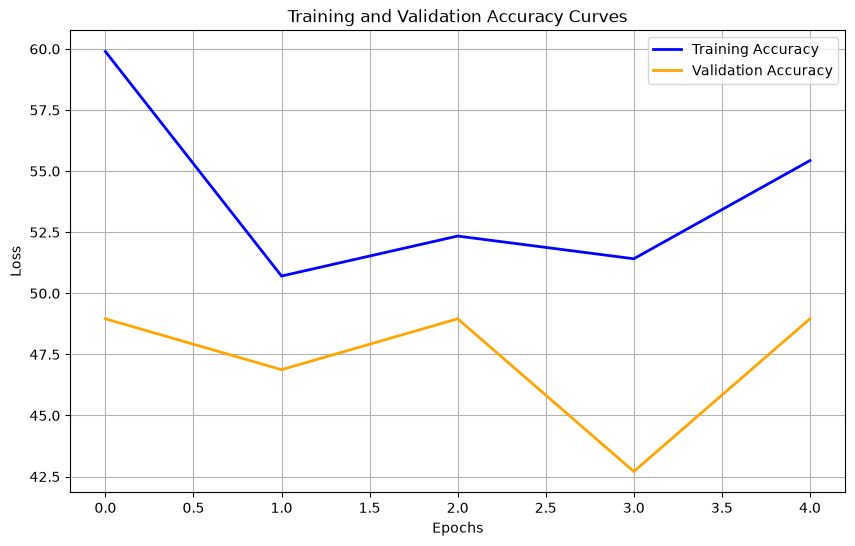

In [288]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(acc, label='Training Accuracy', color='blue', linewidth=2)
plt.plot(acc_val, label='Validation Accuracy', color='orange', linewidth=2)
plt.title('Training and Validation Accuracy Curves')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [275]:
protein_dna_bind_classifier.eval()

running_loss = 0
running_acc = 0

with torch.inference_mode():

    for inputs, targets in test_dataloader:

        test_inputs = inputs.to(device, non_blocking = True) #non blocking to allow CPU to continue querying operations without waiting for data transfers to finish
        test_targets = targets.to(device, non_blocking = True).unsqueeze(dim=1)


        test_logits = protein_dna_bind_classifier(test_inputs)
        test_pred = torch.round(torch.sigmoid(test_logits))

        loss = loss_fn(test_logits, test_targets)
        # calculate accuracy for our interpretation
        test_accuracy = accuracy_fn(test_targets, test_pred)
        
        # Accumulate metrics (detached from graph to save memory)
        running_loss += loss.item()
        running_acc += test_accuracy


    # calculate average epoch metrics across batch (not just final sample)
    avg_loss = running_loss / len(test_dataloader)
    avg_acc = running_acc / len(test_dataloader)


    print(avg_loss, avg_acc)
    

3.170579115549723 15.625


In [ ]:
# sDBM_embeddings = torch.load("sDBM_embeddings.pt")
# ori_one_hot = torch.load("ori_one_hot.pt")
# targets = torch.load("target.pt")